# 04c · Structural growth since 2022 (Prompt 9)

Weather-adjusted demand: actual hourly demand divided by what the 2016–2019 GAM predicts for the same weather and calendar
(`python -m glg.models.growth`). Growth since 2022 compares the latest 12 months with 2022 (FPL and SOCO: with 2023, after Gulf
Power's move; AZPS: window ends 2025-08, see DATA.md). Intervals are 95%: jackknife over baseline years plus a 14-day block bootstrap.
*Beyond trend* subtracts each BA's own 2016–2019 trend extended forward (decision D11).

In [1]:
import numpy as np, polars as pl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from datetime import date
from glg.config import OUTPUTS_DIR, FIGURES_DIR
from glg.models import growth as g
pl.Config(tbl_rows=40, tbl_cols=16, tbl_width_chars=230)
rank = pl.read_csv(g.RANKING_PATH)
monthly = pl.read_parquet(g.MONTHLY_PATH)
annual = pl.read_csv(g.ANNUAL_PATH)

## Ranked: weather-adjusted growth since 2022 vs the 2016–2019 trend

In [2]:
rank.select('ba', 'role', 'headline', 'from_year', 'last12_to', 'growth_pct', 'growth_lo', 'growth_hi', 'mw_added', 'twh_per_yr_added',
            'baseline_trend_pct_yr', 'beyond_trend_pct', 'beyond_trend_lo', 'beyond_trend_hi', 'growth_gbm_pct', 'growth_ddr_pct').with_columns(pl.col(pl.Float64).round(1))

ba,role,headline,from_year,last12_to,growth_pct,growth_lo,growth_hi,mw_added,twh_per_yr_added,baseline_trend_pct_yr,beyond_trend_pct,beyond_trend_lo,beyond_trend_hi,growth_gbm_pct,growth_ddr_pct
str,str,bool,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""AZPS_full""","""sensitivity""",false,2022,"""2026-10-01""",27.6,26.8,28.4,1036.5,9.1,-1.5,33.9,32.4,35.4,28.2,27.8
"""DOPD""","""focus""",false,2022,"""2026-10-01""",24.2,21.8,26.7,51.3,0.4,5.3,7.7,0.7,14.7,22.6,23.6
"""DOM""","""focus""",true,2022,"""2026-10-01""",23.6,22.9,24.3,3208.3,28.1,1.5,18.3,16.5,20.1,23.9,23.7
"""ERCO""","""focus""",true,2022,"""2026-10-01""",19.5,18.8,20.1,9440.4,82.8,2.2,11.7,10.3,13.1,19.3,20.1
"""AZPS""","""focus""",true,2022,"""2025-08-01""",16.6,15.7,17.4,608.3,5.3,-1.5,21.0,19.8,22.2,16.9,15.0
"""AZPS+SRP""","""focus""",true,2022,"""2025-08-01""",13.7,13.0,14.3,1012.8,8.9,-0.2,14.3,13.5,15.1,13.9,12.3
"""BPAT""","""focus""",true,2022,"""2026-10-01""",13.2,12.6,13.8,835.4,7.3,0.5,11.5,10.4,12.6,13.1,12.8
"""SWPP""","""comparison""",true,2022,"""2026-10-01""",10.9,10.4,11.4,3537.8,31.0,1.1,6.8,5.8,7.8,10.9,11.2
"""GCPD""","""focus""",true,2022,"""2026-10-01""",10.6,8.9,12.3,68.3,0.6,3.4,-0.7,-4.2,2.8,9.1,10.3


## The *wrong if* check, first pass: do data-center-heavy regions grow faster than comparison regions?

In [3]:
comparisons = ['MISO', 'NYIS', 'ISNE', 'FPC', 'CPLE', 'CISO', 'PACE', 'FPL']   # D10 comparison set
focus_dc = ['DOM', 'ERCO', 'AZPS+SRP', 'NEVP', 'GCPD', 'BPAT']               # regions with large data-center build-outs
h = rank.filter(pl.col('headline'))
for name, grp in [('data-center-heavy', focus_dc), ('comparison', comparisons)]:
    x = h.filter(pl.col('ba').is_in(grp))
    print(f"{name:18s} median growth {x['growth_pct'].median():5.1f}%   median beyond trend {x['beyond_trend_pct'].median():5.1f}%   n={x.height}")

data-center-heavy  median growth  13.4%   median beyond trend  11.6%   n=6
comparison         median growth   3.3%   median beyond trend   2.6%   n=8


## Hero chart

Top 10 headline BAs by growth since 2022. Line: trailing 12-month weather-adjusted demand index (2019 = 100) with 95% band; dashed:
the BA's own 2016–2019 trend extended forward; grey: median of the comparison regions. Shared y-axis.

2026-11-08 17:49:58,501 INFO hero (light): hero.png, hero.svg


2026-11-08 17:49:59,325 INFO hero (dark): hero_dark.png, hero_dark.svg


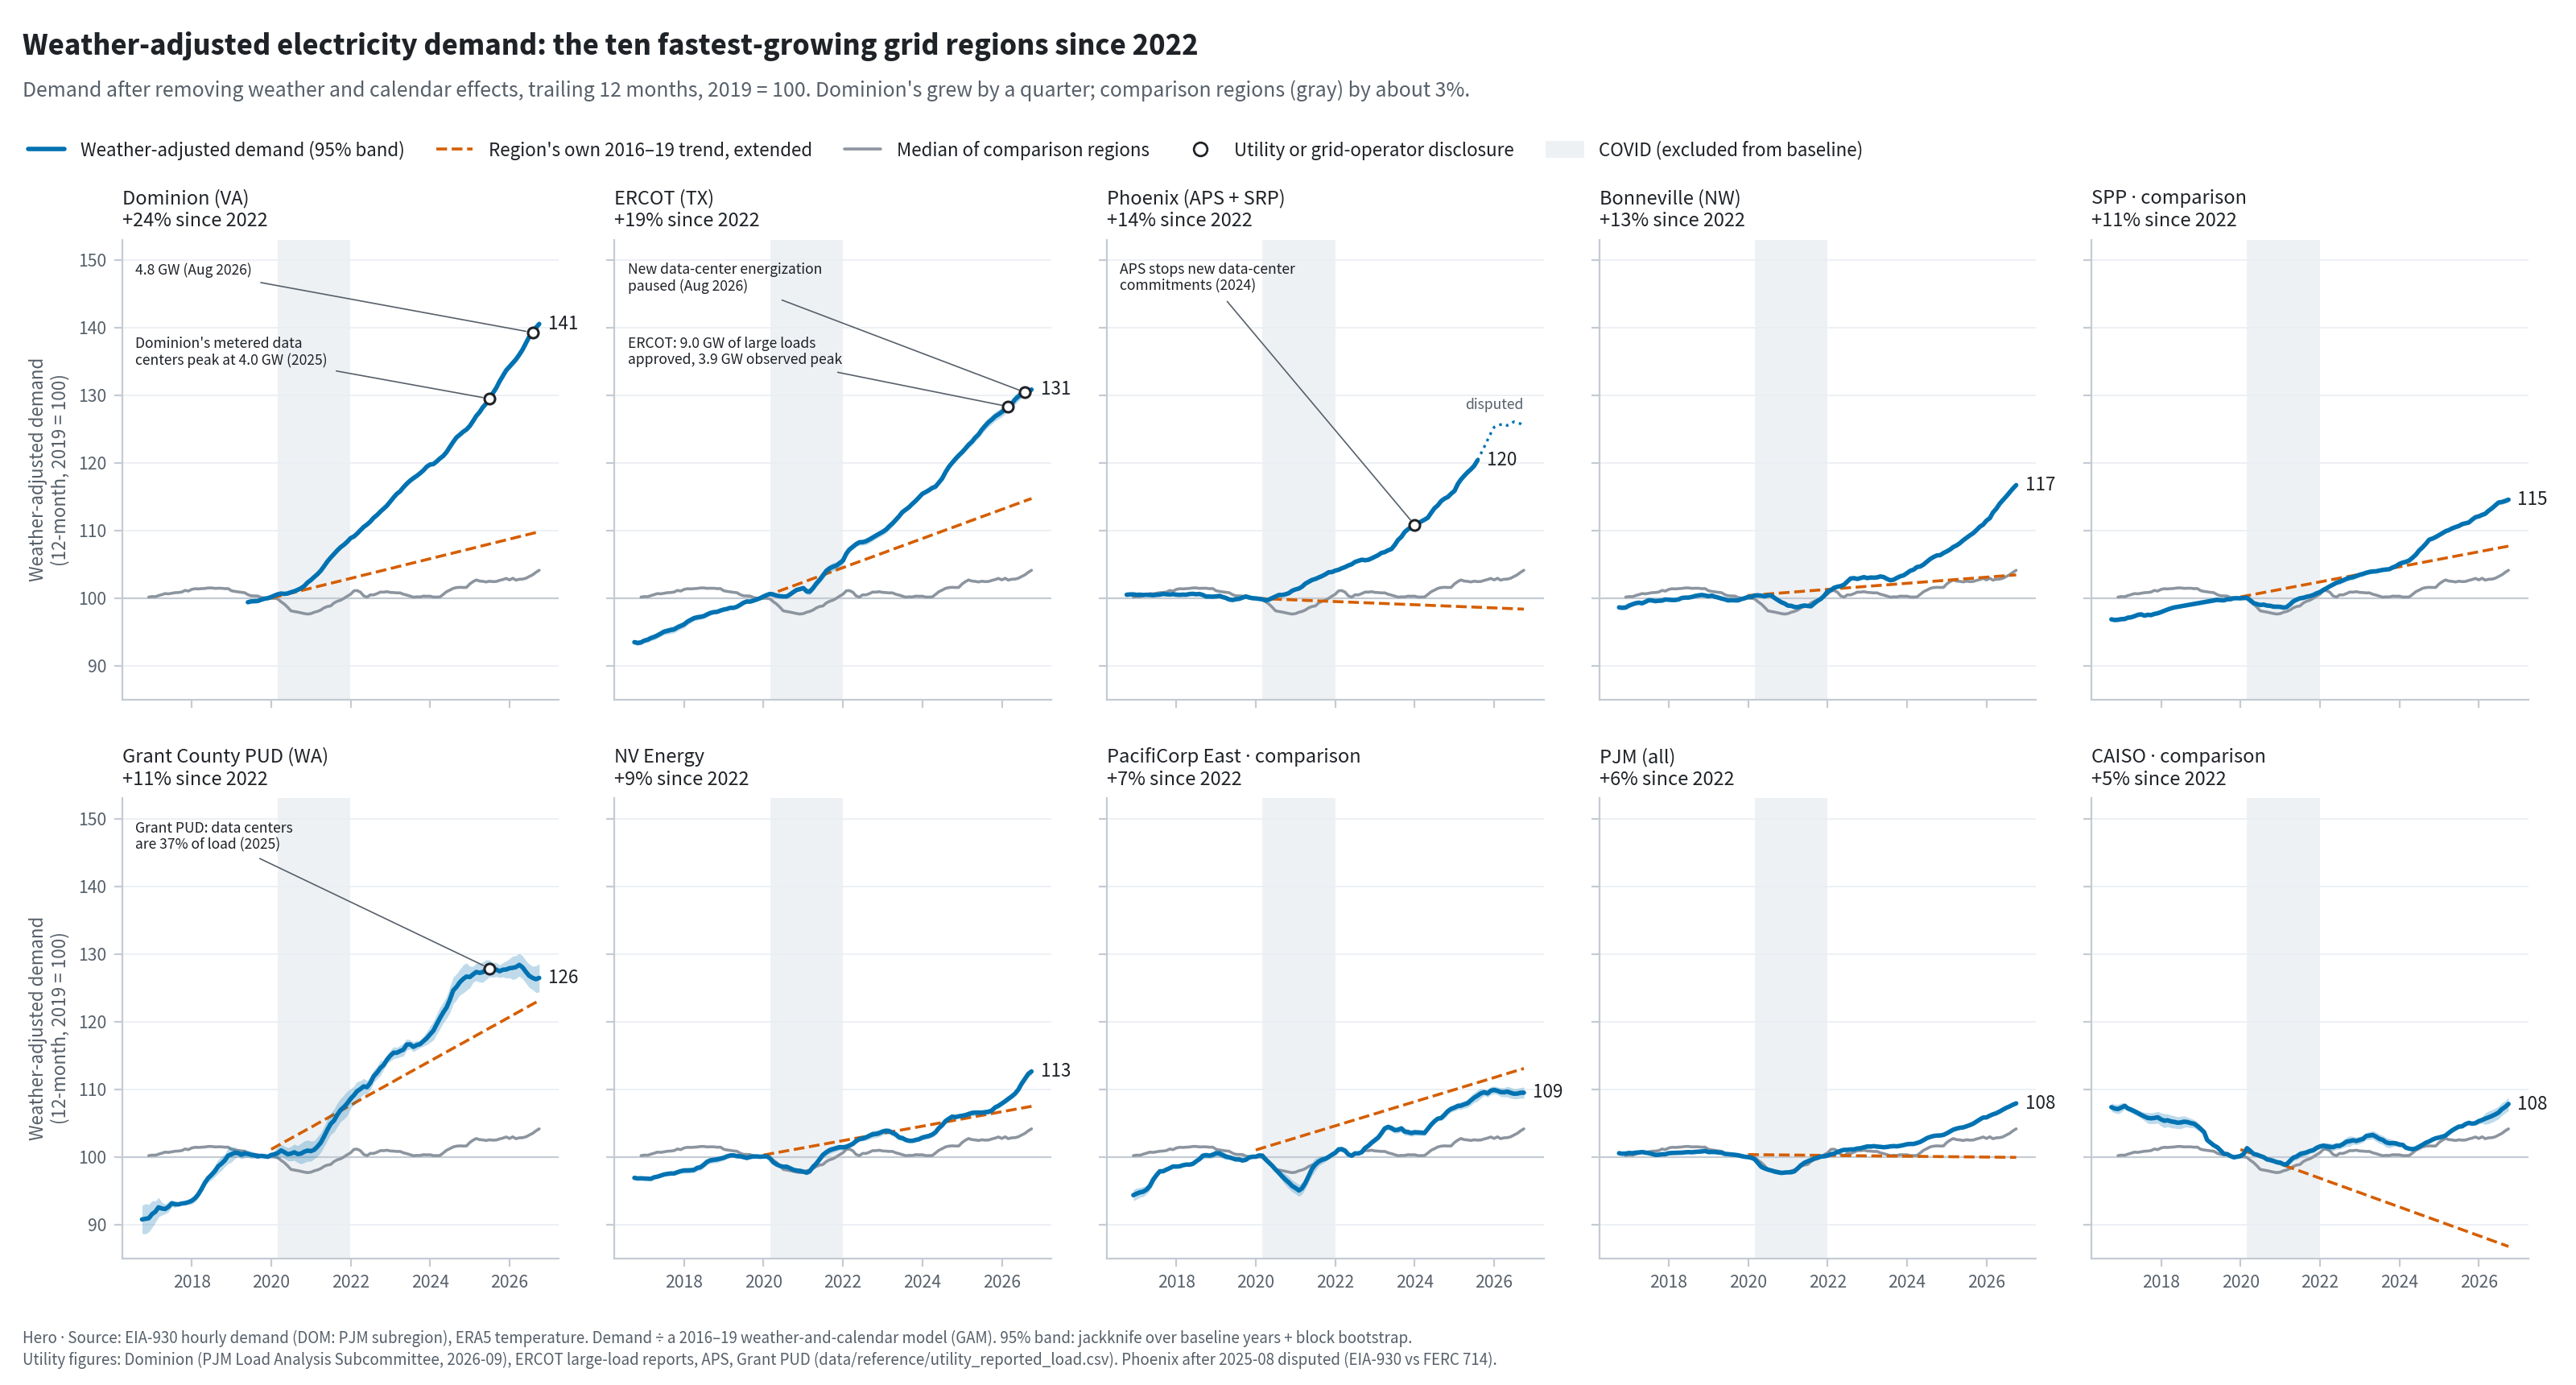

In [4]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['hero'])
Image(filename=str(F.FIGURES_DIR / 'hero.png'), width=900)